Loading MNIST dataset...


100%|██████████| 9.91M/9.91M [00:00<00:00, 13.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 352kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.27MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.85MB/s]


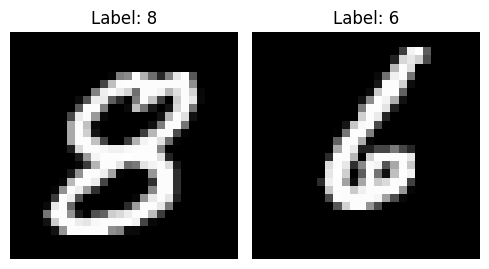

Creating balanced subsamples...


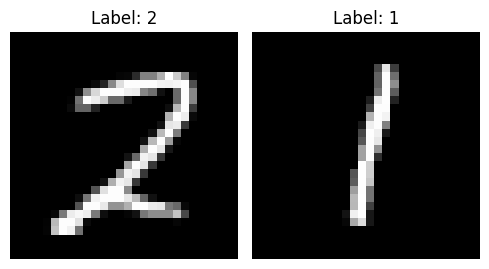

Train set shape: (10000, 28, 28) (should be 10000, 28, 28)
Test set shape: (2000, 28, 28) (should be 2000, 28, 28)

Training set distribution:
Digit 0: 1000 samples
Digit 1: 1000 samples
Digit 2: 1000 samples
Digit 3: 1000 samples
Digit 4: 1000 samples
Digit 5: 1000 samples
Digit 6: 1000 samples
Digit 7: 1000 samples
Digit 8: 1000 samples
Digit 9: 1000 samples

Test set distribution:
Digit 0: 200 samples
Digit 1: 200 samples
Digit 2: 200 samples
Digit 3: 200 samples
Digit 4: 200 samples
Digit 5: 200 samples
Digit 6: 200 samples
Digit 7: 200 samples
Digit 8: 200 samples
Digit 9: 200 samples


In [1]:
import numpy as np
import time
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torchvision import datasets
import random

# ================= LOAD FULL MNIST =================

print("Loading MNIST dataset...")

train_dataset_full = datasets.MNIST(root='./data', train=True, download=True)
test_dataset_full = datasets.MNIST(root='./data', train=False, download=True)

# Convert to numpy arrays
train_images_full = train_dataset_full.data.numpy()
train_labels_full = train_dataset_full.targets.numpy()
test_images_full = test_dataset_full.data.numpy()
test_labels_full = test_dataset_full.targets.numpy()

def show_random_mnist(images, labels, num_images=2):
    """
    Display random MNIST images with their labels
    """
    indices = random.sample(range(len(images)), num_images)

    plt.figure(figsize=(5, 3))

    for i, idx in enumerate(indices):
        img = images[idx]
        label = labels[idx]

        plt.subplot(1, num_images, i+1)
        plt.imshow(img, cmap='gray')
        plt.title(f"Label: {label}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()
show_random_mnist(train_images_full, train_labels_full, num_images=2)

# ================= BALANCED SUBSAMPLING =================
# Training: 1000 examples per digit (10,000 total)
# Testing: 200 examples per digit (2,000 total)

def balanced_subsample(images, labels, samples_per_class):
    """
    Extract balanced subsample with specified number of samples per class
    """
    balanced_images = []
    balanced_labels = []

    for digit in range(10):  # digits 0-9
        # Get indices for current digit
        digit_indices = np.where(labels == digit)[0]

        # Randomly select samples_per_class images
        selected_indices = np.random.choice(digit_indices, samples_per_class, replace=False)

        # Add to balanced dataset
        balanced_images.append(images[selected_indices])
        balanced_labels.append(labels[selected_indices])

    # Combine all digits
    balanced_images = np.vstack(balanced_images)
    balanced_labels = np.hstack(balanced_labels)

    return balanced_images, balanced_labels


print("Creating balanced subsamples...")
train_images, train_labels = balanced_subsample(train_images_full, train_labels_full, 1000)
test_images, test_labels = balanced_subsample(test_images_full, test_labels_full, 200)
show_random_mnist(train_images, train_labels, 2)

print(f"Train set shape: {train_images.shape} (should be 10000, 28, 28)")
print(f"Test set shape: {test_images.shape} (should be 2000, 28, 28)")

# Verify balanced distribution
print("\nTraining set distribution:")
for digit in range(10):
    count = np.sum(train_labels == digit)
    print(f"Digit {digit}: {count} samples")

print("\nTest set distribution:")
for digit in range(10):
    count = np.sum(test_labels == digit)
    print(f"Digit {digit}: {count} samples")

# ================= NORMALIZATION =================
# Scale pixels from [0,255] → [0,1]

train_images = train_images / 255.0
test_images = test_images / 255.0

In [2]:
import tensorflow as tf
import numpy as np
import time

from tensorflow.keras import layers, models

2026-04-29 13:42:27.820874: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777470147.985020      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777470148.031889      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777470148.437389      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777470148.437436      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777470148.437439      57 computation_placer.cc:177] computation placer alr

In [57]:
model = models.Sequential([
    layers.Conv2D(6, (5,5), activation='relu', input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(16, (5,5), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Flatten(),
    
    layers.Dense(120, activation='relu'),
    layers.Dense(84, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [58]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [59]:
start_train = time.time()

history = model.fit(
    train_images, train_labels,
    epochs=10,
    batch_size=64,
    verbose=1
)

end_train = time.time()

Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5759 - loss: 1.3097
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9116 - loss: 0.2835
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9475 - loss: 0.1728
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9621 - loss: 0.1221
Epoch 5/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9693 - loss: 0.0967
Epoch 6/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9757 - loss: 0.0803
Epoch 7/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9801 - loss: 0.0685
Epoch 8/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9842 - loss: 0.0486
Epoch 9/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9880 - loss: 0.0386
Epoch 10/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9928 - loss: 0.0255


In [60]:
start_test = time.time()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)

end_test = time.time()

print(f"\nAccuracy: {test_acc*100:.2f}%")
print(f"Training time: {(end_train - start_train)*1000:.2f} ms")
print(f"Testing time: {(end_test - start_test)*1000:.2f} ms")


Accuracy: 97.25%
Training time: 24278.85 ms
Testing time: 475.57 ms
